In [1]:
import cantera as ct

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# Task 1 - $T(Z)$ at  Increasing Scalar Dissipation Rate

In [2]:
def solve_counterflow(strain_rate, mechanism="h2o2.yaml",
                      fuel="H2", T_fuel=300.0, T_ox=300.0,
                      p=101325.0, width=0.02):
    """
    Solve a H2/air counterflow diffusion flame at a given strain rate.

    Parameters
    ----------
    strain_rate : float
        Target strain rate in 1/s.
    mechanism : str
        Cantera mechanism file.
    fuel : str
        Fuel species name.
    T_fuel : float
        Fuel stream temperature in K.
    T_ox : float
        Oxidiser stream temperature in K.
    p : float
        Pressure in Pa.
    width : float
        Domain width in m.

    Returns
    -------
    cantera.CounterflowDiffusionFlame
        Solved flame object.
    """
    gas = ct.Solution(mechanism)

    fuel_stream = f"{fuel}:1"
    ox_stream   = "O2:0.21, N2:0.79"

    flame = ct.CounterflowDiffusionFlame(gas, width=width)
    flame.fuel_inlet.X       = fuel_stream
    flame.fuel_inlet.T       = T_fuel
    flame.oxidizer_inlet.X   = ox_stream
    flame.oxidizer_inlet.T   = T_ox
    flame.P                  = p

    # Set mass fluxes to achieve target strain rate
    # For symmetric counterflow: a ≈ 2 * mdot / (rho * L/2)
    gas.TPX = T_fuel, p, fuel_stream
    rho_f   = gas.density
    gas.TPX = T_ox,   p, ox_stream
    rho_ox  = gas.density
    mdot    = strain_rate * 0.5 * width * 0.5 * (rho_f + rho_ox)
    flame.fuel_inlet.mdot      = mdot
    flame.oxidizer_inlet.mdot  = mdot

    flame.set_refine_criteria(ratio=3, slope=0.05, curve=0.1)
    flame.solve(loglevel=0, auto=True)

    return flame

In [8]:
df_flame = flame.to_pandas()
df_flame.head()

,grid,velocity,spreadRate,Lambda,T,density,X_H2,X_H,X_O,X_O2,X_OH,X_H2O,X_HO2,X_H2O2,X_AR,X_N2
0,0.000000,76.554167,9.743717e-18,-2.084724e+06,300.0,0.081894,1.0,3.291891e-15,0.0,1.616098e-15,6.989079e-18,0.000000e+00,0.0,1.586003e-19,2.349687e-17,0.0
1,0.000426,76.493953,1.415012e+02,-2.084724e+06,300.0,0.081894,1.0,3.287032e-15,0.0,1.616098e-15,7.982616e-19,7.055326e-20,0.0,1.586003e-19,2.349687e-17,0.0
2,0.000851,76.313314,2.830024e+02,-2.084724e+06,300.0,0.081894,1.0,3.279319e-15,0.0,1.616098e-15,0.000000e+00,0.000000e+00,0.0,1.586003e-19,2.349687e-17,0.0
3,0.001277,76.012247,4.245036e+02,-2.084724e+06,300.0,0.081894,1.0,3.270038e-15,0.0,1.616098e-15,0.000000e+00,0.000000e+00,0.0,1.586003e-19,2.349687e-17,0.0
4,0.001702,75.590754,5.660047e+02,-2.084724e+06,300.0,0.081894,1.0,3.259876e-15,0.0,1.616098e-15,0.000000e+00,0.000000e+00,0.0,1.586003e-19,2.349687e-17,0.0


In [12]:
df_flame.shape

(248, 16)

In [11]:
df_flame.info()

<class 'pandas.DataFrame'>
RangeIndex: 248 entries, 0 to 247
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   grid        248 non-null    float64
 1   velocity    248 non-null    float64
 2   spreadRate  248 non-null    float64
 3   Lambda      248 non-null    float64
 4   T           248 non-null    float64
 5   density     248 non-null    float64
 6   X_H2        248 non-null    float64
 7   X_H         248 non-null    float64
 8   X_O         248 non-null    float64
 9   X_O2        248 non-null    float64
 10  X_OH        248 non-null    float64
 11  X_H2O       248 non-null    float64
 12  X_HO2       248 non-null    float64
 13  X_H2O2      248 non-null    float64
 14  X_AR        248 non-null    float64
 15  X_N2        248 non-null    float64
dtypes: float64(16)
memory usage: 31.1 KB


Text(0, 0.5, 'Temperature (K)')

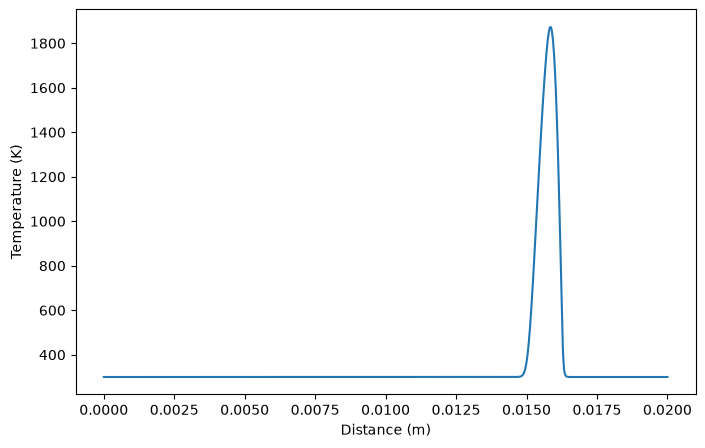

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(df_flame["grid"], df_flame["T"], label="Temperature (K)")
plt.xlabel("Distance (m)")
plt.ylabel("Temperature (K)")


Text(0, 0.5, 'Temperature (K)')

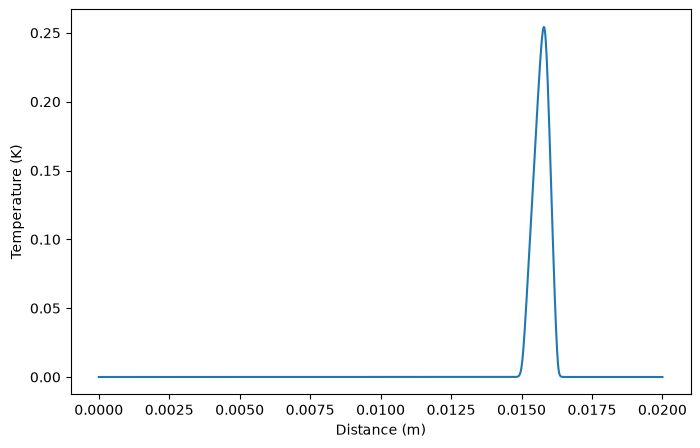

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(df_flame["grid"], df_flame["X_H2O"], label="Temperature (K)")
plt.xlabel("Distance (m)")
plt.ylabel("Temperature (K)")


In [ ]:
for a in [50, 100, 500, 1000]:
    flame = solve_counterflow(a)
    print(f"target a = {a:5d} 1/s | T_max = {flame.T.max():7.1f} K | "
          f"grid points = {len(flame.grid)} | a_max = {flame.strain_rate('max'):8.1f} 1/s")


target a =    50 1/s | T_max =  2365.3 K | grid points = 218 | a_max =    827.0 1/s
target a =   100 1/s | T_max =  2273.3 K | grid points = 230 | a_max =   1536.4 1/s
target a =   500 1/s | T_max =  2003.2 K | grid points = 244 | a_max =   6222.6 1/s
target a =  1000 1/s | T_max =  1873.1 K | grid points = 248 | a_max =  11592.5 1/s


In [36]:
def extract_TZ_profile(flame, fuel="H2", oxidizer="O2:1, N2:3.76"):
    """
    Extract temperature and mixture fraction profiles from a solved flame.

    Returns
    -------
    Z : numpy.ndarray
        Mixture fraction at each grid point.
    T : numpy.ndarray
        Temperature in K at each grid point.
    chi_st : float
        Scalar dissipation rate at the stoichiometric surface (1/s).
    """
    Z   = flame.mixture_fraction("Bilger")        # flame method: element or "Bilger"
    T   = flame.T

    # Z_st from a separate gas object: gas method takes (fuel, oxidizer)
    solution = ct.Solution(flame.gas.source)
    solution.set_equivalence_ratio(1.0, fuel, oxidizer)
    Z_st   = solution.mixture_fraction(fuel, oxidizer)

    # chi = 2 D (dZ/dx)^2 is not provided by Cantera, so compute it from Z(x)
    D      = flame.thermal_conductivity / (flame.density * flame.cp_mass)
    chi    = 2 * D * np.gradient(Z, flame.grid) ** 2     # χ(x), 1/s
    idx_st = np.argmin(np.abs(Z - Z_st))
    chi_st = chi[idx_st]

    return Z, T, chi_st


In [37]:
flame = solve_counterflow(100)
Z, T, chi_st = extract_TZ_profile(flame)
print(Z.shape, T.shape, f"chi_st = {chi_st:.3f} 1/s", f"T_max = {T.max():.0f} K")
print(f"Z from {Z[0]:.2f} to {Z[-1]:.2f}")


(230,) (230,) chi_st = 1.807 1/s T_max = 2273 K
Z from 1.00 to 0.00


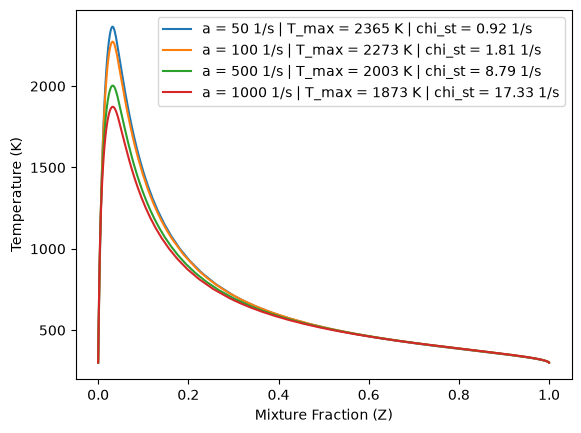

In [42]:
for a in [50, 100, 500, 1000]:
    flame = solve_counterflow(a)
    Z, T, chi_st = extract_TZ_profile(flame)
    plt.plot(Z, T, label=f"a = {a} 1/s | T_max = {T.max():.0f} K | chi_st = {chi_st:.2f} 1/s")

plt.xlabel("Mixture Fraction (Z)")
plt.ylabel("Temperature (K)")
plt.legend()

In [49]:
def equilibrium_T_of_Z(Z_range, fuel="H2", T_fuel=300.0, T_ox=300.0,
                       p=101325.0, mechanism="h2o2.yaml",
                       oxidizer="O2:0.21, N2:0.79"):
    """
    Compute the equilibrium temperature as a function of mixture fraction.

    For each Z, the mixture is the linear blend of fuel and oxidiser streams.
    The result is the upper-bound temperature envelope for any non-premixed flame.

    Parameters
    ----------
    Z_range : array-like
        Mixture fraction values in [0, 1].

    Returns
    -------
    numpy.ndarray
        T_eq in K at each Z.
    """
    Z_range = np.asarray(Z_range, dtype=float)
    gas     = ct.Solution(mechanism)
    T_eq    = np.zeros(len(Z_range))

    # Fuel and oxidiser streams: mass fractions and specific enthalpy
    gas.TPX = T_fuel, p, f"{fuel}:1"
    Y_fuel, h_fuel = gas.Y.copy(), gas.enthalpy_mass

    gas.TPX = T_ox, p, oxidizer
    Y_ox,   h_ox   = gas.Y.copy(), gas.enthalpy_mass

    for i, Z in enumerate(Z_range):
        Y_mix   = Z * Y_fuel + (1.0 - Z) * Y_ox
        h_mix   = Z * h_fuel + (1.0 - Z) * h_ox            # blended enthalpy
        gas.TPY = 0.5 * (T_fuel + T_ox), p, Y_mix          # sets the composition
        gas.HPY = h_mix, p, Y_mix                          # state with the blended enthalpy
        gas.equilibrate("HP")
        T_eq[i] = gas.T

    return T_eq


T_max = 2402.4 K at Z = 0.030   (Z_st = 0.0285)


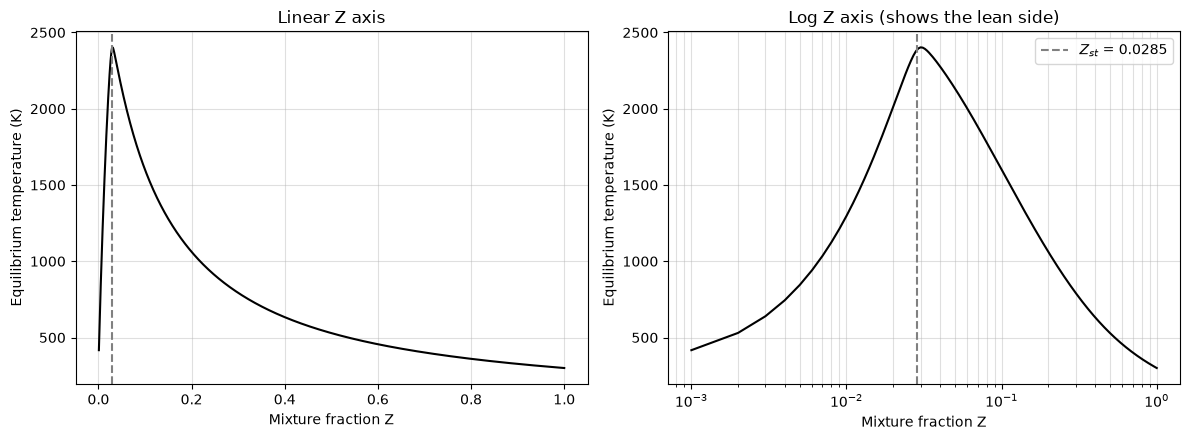

In [50]:
Z = np.linspace(0, 1, 1001)
T = equilibrium_T_of_Z(Z)

# Z_st for H2/air from a separate gas object
ref = ct.Solution("h2o2.yaml")
ref.set_equivalence_ratio(1.0, "H2", "O2:1, N2:3.76")
Z_st = ref.mixture_fraction("H2", "O2:1, N2:3.76")

# Checks
assert np.isclose(T[0], 300.0) and np.isclose(T[-1], 300.0)       # pure air / pure fuel stay at 300 K
assert np.isclose(equilibrium_T_of_Z([Z_st])[0], 2387.6, atol=1.0)  # equals phi = 1 flame T
print(f"T_max = {T.max():.1f} K at Z = {Z[np.argmax(T)]:.3f}   (Z_st = {Z_st:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, scale in zip(axes, ["linear", "log"]):
    ax.plot(Z[1:], T[1:], "k")
    ax.axvline(Z_st, ls="--", color="gray", label=f"$Z_{{st}}$ = {Z_st:.4f}")
    ax.set(xscale=scale, xlabel="Mixture fraction Z", ylabel="Equilibrium temperature (K)")
    ax.grid(which="both", alpha=0.4)
axes[0].set_title("Linear Z axis")
axes[1].set_title("Log Z axis (shows the lean side)")
axes[1].legend()
plt.tight_layout()


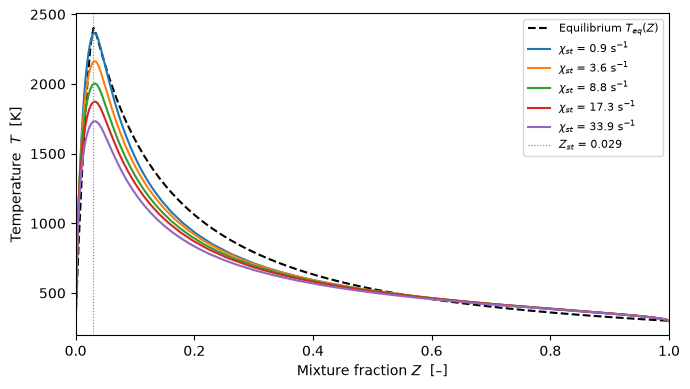

In [52]:
import matplotlib.pyplot as plt

strain_rates = [50, 200, 500, 1000, 2000]   # 1/s — adjust to your mechanism

fig, ax = plt.subplots(figsize=(7, 4))

Z_eq  = np.linspace(0, 1, 200)
T_eq  = equilibrium_T_of_Z(Z_eq)
ax.plot(Z_eq, T_eq, "k--", lw=1.5, label="Equilibrium $T_{eq}(Z)$")

for a in strain_rates:
    flame      = solve_counterflow(a)
    Z, T, chi  = extract_TZ_profile(flame)
    ax.plot(Z, T, label=f"$\\chi_{{st}}$ = {chi:.1f} s$^{{-1}}$")

ax.axvline(Z_st, ls=":", color="gray", lw=0.8, label=f"$Z_{{st}}$ = {Z_st:.3f}")
ax.set_xlabel("Mixture fraction $Z$  [–]")
ax.set_ylabel("Temperature  $T$  [K]")
ax.legend(fontsize=8)
ax.set_xlim(0, 1)
fig.tight_layout()
#fig.savefig("figures/part2_T_vs_Z.pdf")